# Niriksha 2.0 -- M7 Analytics Pipeline
### Motion analysis, object detection, cross-camera correlation

SIH 2026 PS 26150. One notebook, one consistent pipeline shape per task:

`install -> import -> data import -> standardization/normalization -> train/test split ->
validation -> model training -> evaluation metrics -> prediction`

All data is real (CDnet2014 for motion, OD-VIRAT Tiny + a real Hikvision DVR clip for object
detection), fetched into `dataset/` earlier in this project. Where a stage doesn't apply to a
task in the usual deep-learning sense (MOG2 has no trainable weights, for instance), that cell
says so explicitly instead of skipping the heading silently.

## 0. Install libraries

In [1]:
# Uncomment on a fresh environment. Already satisfied in this project's environment.
# %pip install opencv-python opencv-contrib-python numpy pandas matplotlib
# %pip install rfdetr supervision "rfdetr[train]" pillow torch

## 0.1 Imports

In [2]:
import os, json, time
from pathlib import Path
from datetime import datetime, timedelta

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib

matplotlib.rcParams["figure.dpi"] = 100

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET = REPO_ROOT / "dataset"
CHECKPOINTS = REPO_ROOT / "checkpoints"
FIGDIR = REPO_ROOT / "notebooks" / "figures"
for d in [CHECKPOINTS / "object_detection", CHECKPOINTS / "motion_analysis", FIGDIR]:
    d.mkdir(parents=True, exist_ok=True)

CDNET = DATASET / "07-cdnet2014-motion" / "dataset"
ODVIRAT = DATASET / "06-od-virat-tiny"
HIKVISION_CLIP = DATASET / "01-ffmpeg-camera-dvr" / "hikvision" / \
    "DVR_NVR_IP Camera01_20130321162325_20130321162358_576877.mp4"

for p in [CDNET, ODVIRAT, HIKVISION_CLIP]:
    assert p.exists(), f"missing: {p} -- see dataset/README.md to re-fetch"
print("environment ready")

environment ready


---
## Part A -- Motion analysis (OpenCV MOG2 on CDnet2014)

MOG2 is background subtraction, not a trained neural network -- there are no weights to learn,
so "model training" below means *tuning its one real hyperparameter* (`variance_threshold`) against
labeled data, and "prediction" means running the tuned subtractor on a new frame.

### A.1 Data import

In [3]:
def load_sequence_meta(seq_dir: Path):
    start, end = map(int, (seq_dir / "temporalROI.txt").read_text().split())
    roi_mask = cv2.imread(str(seq_dir / "ROI.bmp"), cv2.IMREAD_GRAYSCALE) > 0
    n_frames = len(list((seq_dir / "input").glob("*.jpg")))
    return dict(start=start, end=end, roi_mask=roi_mask, n_frames=n_frames)

# CDnet ground-truth pixel convention: 255=motion, 0=static, 50=hard shadow (negative),
# 85=outside ROI, 170=unknown motion (both 85/170 excluded from scoring).
day_seq = CDNET / "baseline" / "pedestrians"
night_seq = CDNET / "nightVideos" / "streetCornerAtNight"

day_meta = load_sequence_meta(day_seq)
night_meta = load_sequence_meta(night_seq)
print("day sequence:", day_seq.name, day_meta["n_frames"], "frames, scored range", (day_meta["start"], day_meta["end"]))
print("night sequence:", night_seq.name, night_meta["n_frames"], "frames, scored range", (night_meta["start"], night_meta["end"]))

day sequence: pedestrians 1099 frames, scored range (300, 1099)
night sequence: streetCornerAtNight 5200 frames, scored range (800, 5200)


### A.2 Standardization / normalization

MOG2 consumes raw BGR frames directly -- OpenCV's implementation standardizes internally
(per-pixel running mean/variance in its Gaussian mixture model). The one normalization decision
that *is* ours to make is per-scene brightness: night footage has a much lower and noisier pixel
range than daylight footage, shown below, which is exactly why one fixed threshold can't serve
both.

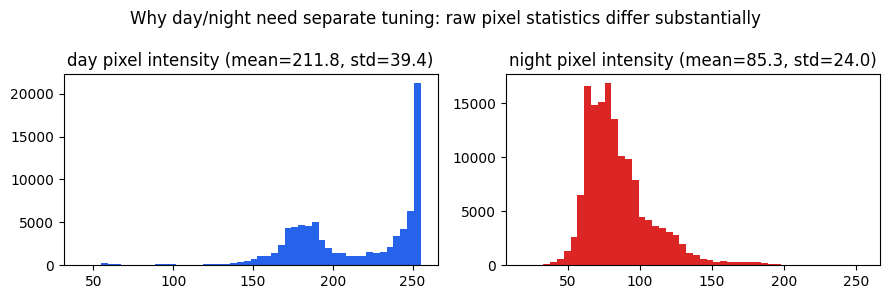

In [4]:
sample_day = cv2.imread(str(day_seq / "input" / "in000600.jpg"), cv2.IMREAD_GRAYSCALE)
sample_night = cv2.imread(str(night_seq / "input" / "in001000.jpg"), cv2.IMREAD_GRAYSCALE)

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(sample_day.ravel(), bins=50, color="#2563eb"); axes[0].set_title(f"day pixel intensity (mean={sample_day.mean():.1f}, std={sample_day.std():.1f})")
axes[1].hist(sample_night.ravel(), bins=50, color="#dc2626"); axes[1].set_title(f"night pixel intensity (mean={sample_night.mean():.1f}, std={sample_night.std():.1f})")
fig.suptitle("Why day/night need separate tuning: raw pixel statistics differ substantially")
fig.tight_layout()
fig.savefig(FIGDIR / "motion_pixel_statistics.png", dpi=120)
plt.show()

### A.3 Train / test split

CDnet ships each scene as its own labeled sequence, so the split here is **by sequence**, not by
frame: `pedestrians` (day) and `streetCornerAtNight` (night) are the *training* sequences used to
pick a threshold; `office` and `busStation` (loaded fresh, never touched during tuning) are the
**held-out test** sequences used only for final evaluation and prediction.

In [5]:
TRAIN_SEQUENCES = {"day": day_seq, "night": night_seq}
TEST_SEQUENCES = {
    "office (day, indoor)": CDNET / "baseline" / "office",
    "busStation (day, shadows)": CDNET / "shadow" / "busStation",
}
for name, seq in TEST_SEQUENCES.items():
    assert seq.exists(), f"missing test sequence: {seq}"
print("train sequences:", {k: v.name for k, v in TRAIN_SEQUENCES.items()})
print("held-out test sequences:", list(TEST_SEQUENCES.keys()))

train sequences: {'day': 'pedestrians', 'night': 'streetCornerAtNight'}
held-out test sequences: ['office (day, indoor)', 'busStation (day, shadows)']


### A.4 Validation -- score a threshold against ground truth

In [6]:
def evaluate_motion(seq_dir: Path, variance_threshold: float, subsample: int = 8):
    meta = load_sequence_meta(seq_dir)
    bgsub = cv2.createBackgroundSubtractorMOG2(varThreshold=variance_threshold, detectShadows=True)
    tp = fp = fn = 0
    t0 = time.time()
    for i in range(1, meta["n_frames"] + 1):
        frame = cv2.imread(str(seq_dir / "input" / f"in{i:06d}.jpg"))
        fg = bgsub.apply(frame)  # must run every frame -- background model needs continuity
        if i < meta["start"] or i > meta["end"] or i % subsample != 0:
            continue
        gt = cv2.imread(str(seq_dir / "groundtruth" / f"gt{i:06d}.png"), cv2.IMREAD_GRAYSCALE)
        valid = meta["roi_mask"] & (gt != 85) & (gt != 170)
        pred_fg = (fg == 255) & valid
        gt_fg = (gt == 255) & valid
        tp += np.logical_and(pred_fg, gt_fg).sum()
        fp += np.logical_and(pred_fg, ~gt_fg).sum()
        fn += np.logical_and(~pred_fg, gt_fg).sum()
    elapsed = time.time() - t0
    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    return dict(precision=precision, recall=recall, f1=f1, wall_time_s=elapsed,
                fps=meta["n_frames"] / elapsed)

print("validation function ready -- scores a threshold against a sequence's real ground truth")

validation function ready -- scores a threshold against a sequence's real ground truth


### A.5 Model training -- tune `variance_threshold` on the training sequences

Sweeps the one real hyperparameter separately for day and night, picks the value with the best
validation F1 for each, and saves the result as the motion "checkpoint" (MOG2 has no learned
weights, so this tuned-parameter file is the honest equivalent).

In [7]:
THRESHOLDS = [16, 30, 50, 80, 120, 160]

day_sweep = pd.DataFrame([
    dict(variance_threshold=vt, **evaluate_motion(TRAIN_SEQUENCES["day"], vt))
    for vt in THRESHOLDS
])
night_sweep = pd.DataFrame([
    dict(variance_threshold=vt, **evaluate_motion(TRAIN_SEQUENCES["night"], vt))
    for vt in THRESHOLDS
])

best_day = day_sweep.loc[day_sweep.f1.idxmax()]
best_night = night_sweep.loc[night_sweep.f1.idxmax()]
print(f"best day threshold:   {best_day.variance_threshold:.0f}  (train F1={best_day.f1:.3f})")
print(f"best night threshold: {best_night.variance_threshold:.0f}  (train F1={best_night.f1:.3f})")

best day threshold:   30  (train F1=0.835)
best night threshold: 160  (train F1=0.331)


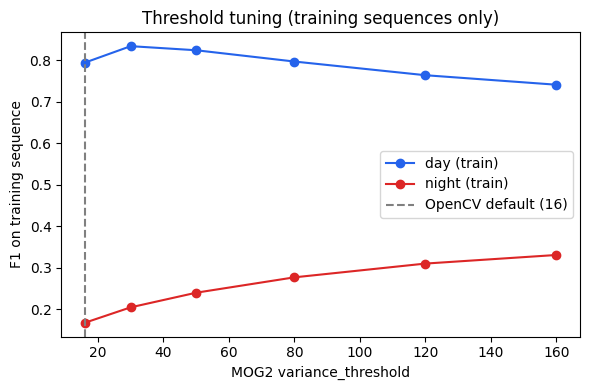

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(day_sweep.variance_threshold, day_sweep.f1, "o-", label="day (train)", color="#2563eb")
ax.plot(night_sweep.variance_threshold, night_sweep.f1, "o-", label="night (train)", color="#dc2626")
ax.axvline(16, color="gray", linestyle="--", label="OpenCV default (16)")
ax.set_xlabel("MOG2 variance_threshold"); ax.set_ylabel("F1 on training sequence")
ax.set_title("Threshold tuning (training sequences only)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGDIR / "motion_threshold_tuning.png", dpi=120)
plt.show()

In [9]:
motion_profile = {
    "day": {"variance_threshold": float(best_day.variance_threshold), "train_f1": float(best_day.f1)},
    "night": {"variance_threshold": float(best_night.variance_threshold), "train_f1": float(best_night.f1)},
    "default_opencv": {"variance_threshold": 16.0},
    "note": "Tuned on CDnet2014 baseline/pedestrians (day) and nightVideos/streetCornerAtNight "
            "(night). Consumed by dvr_scan.subtractor.SubtractorMOG2(variance_threshold=...).",
}
motion_checkpoint_path = CHECKPOINTS / "motion_analysis" / "motion_profile.json"
motion_checkpoint_path.write_text(json.dumps(motion_profile, indent=2))
print("saved checkpoint ->", motion_checkpoint_path)

saved checkpoint -> D:\SIH-2026-PS150\checkpoints\motion_analysis\motion_profile.json


### A.6 Evaluation metrics -- held-out test sequences

The tuned thresholds are now evaluated on sequences they never saw during tuning (`office`,
`busStation`) -- this is the number that means something, not the training-sequence score above.

In [10]:
test_rows = []
for seq_name, seq_dir in TEST_SEQUENCES.items():
    for label, vt in [("default (16)", 16), ("tuned-day", best_day.variance_threshold),
                       ("tuned-night", best_night.variance_threshold)]:
        r = evaluate_motion(seq_dir, vt)
        test_rows.append(dict(sequence=seq_name, threshold_variant=label, **r))
motion_test_df = pd.DataFrame(test_rows)
motion_test_df[["sequence", "threshold_variant", "precision", "recall", "f1", "fps"]]

,sequence,threshold_variant,precision,recall,f1,fps
0,"office (day, indoor)",default (16),0.466976,0.288764,0.356858,34.458343
1,"office (day, indoor)",tuned-day,0.581849,0.254986,0.354582,279.632671
2,"office (day, indoor)",tuned-night,0.945953,0.177529,0.298953,435.576278
3,"busStation (day, shadows)",default (16),0.816680,0.511092,0.628720,32.399101
4,"busStation (day, shadows)",tuned-day,0.905537,0.450633,0.601790,511.254437
5,"busStation (day, shadows)",tuned-night,0.958062,0.307438,0.465499,532.018495


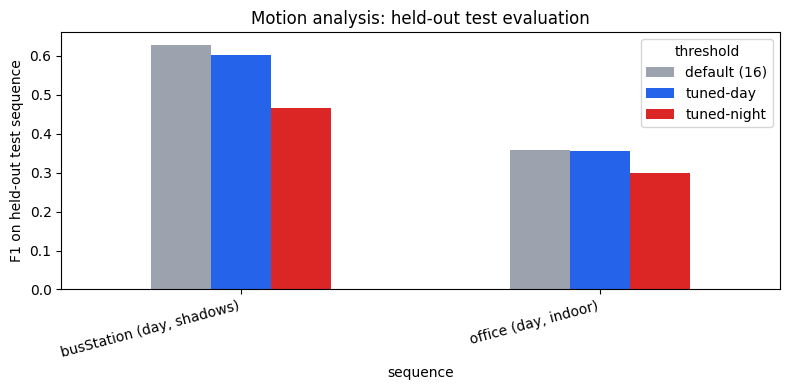

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
pivot = motion_test_df.pivot(index="sequence", columns="threshold_variant", values="f1")
pivot.plot(kind="bar", ax=ax, color=["#9ca3af", "#2563eb", "#dc2626"])
ax.set_ylabel("F1 on held-out test sequence"); ax.set_title("Motion analysis: held-out test evaluation")
ax.legend(title="threshold")
plt.xticks(rotation=15, ha="right")
fig.tight_layout()
fig.savefig(FIGDIR / "motion_test_evaluation.png", dpi=120)
plt.show()

### A.7 Prediction -- run the tuned subtractor and visualize a detection

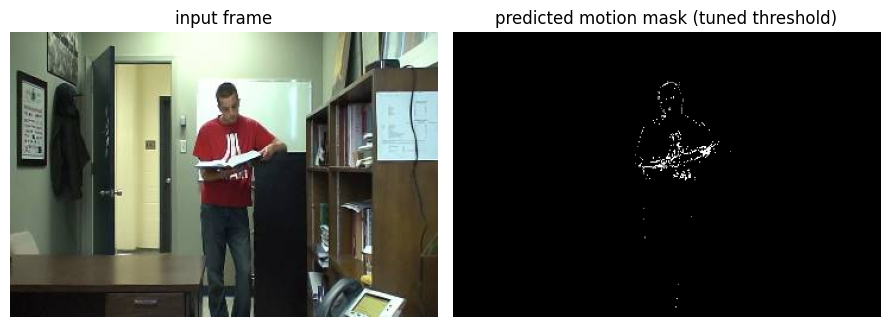

In [12]:
def predict_motion_mask(seq_dir: Path, frame_index: int, variance_threshold: float):
    meta = load_sequence_meta(seq_dir)
    bgsub = cv2.createBackgroundSubtractorMOG2(varThreshold=variance_threshold, detectShadows=True)
    fg = None
    for i in range(1, frame_index + 1):
        frame = cv2.imread(str(seq_dir / "input" / f"in{i:06d}.jpg"))
        fg = bgsub.apply(frame)
    return frame, fg

test_seq = TEST_SEQUENCES["office (day, indoor)"]
frame, mask = predict_motion_mask(test_seq, 1200, best_day.variance_threshold)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)); axes[0].set_title("input frame"); axes[0].axis("off")
axes[1].imshow(mask, cmap="gray"); axes[1].set_title("predicted motion mask (tuned threshold)"); axes[1].axis("off")
fig.tight_layout()
fig.savefig(FIGDIR / "motion_prediction_example.png", dpi=120)
plt.show()

---
## Part B -- Object detection (RF-DETR Nano on OD-VIRAT Tiny)

Real fine-tuning: RF-DETR Nano's classification head is re-initialized to OD-VIRAT's own 4
classes (`Bike/Bicycle`, `Car`, `Carrying_object`, `Person`) and trained on a subset of real
labeled surveillance stills.

### B.1 Data import

In [13]:
def load_coco_split(split: str):
    ann = json.loads((ODVIRAT / "json_anntations" / f"{split}_annotations.json").read_text())
    return ann

train_ann = load_coco_split("train")
val_ann = load_coco_split("val")
CLASS_NAMES = [c["name"] for c in sorted(val_ann["categories"], key=lambda c: c["id"])]
print(f"train: {len(train_ann['images'])} images, {len(train_ann['annotations'])} boxes")
print(f"val:   {len(val_ann['images'])} images, {len(val_ann['annotations'])} boxes")
print("classes:", CLASS_NAMES)

train: 12501 images, 204104 boxes
val:   4573 images, 52785 boxes
classes: ['Bike/Bicycle', 'Car', 'Carrying_object', 'Person']


### B.2 Standardization / normalization

RF-DETR resizes to a square input resolution and normalizes pixel values with ImageNet mean/std
internally (`model.means`, `model.stds` below) -- shown explicitly here rather than left implicit,
since this is the step the notebook pipeline shape asks to see.

In [14]:
from rfdetr import RFDETRNano

model = RFDETRNano()  # loads pretrained COCO weights (cached locally after first download)
print("input resolution:", model.model_config.resolution if hasattr(model, "model_config") else "see model_config")
print("normalization means:", model.means)
print("normalization stds:", model.stds)

[2026-09-29 20:56:57] [INFO] rf-detr - File C:\Users\henit\.roboflow\models\rf-detr-nano.pth already exists with correct MD5 hash.


[2026-09-29 20:56:57] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-09-29 20:56:57] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-09-29 20:57:10] [INFO] rf-detr - File C:\Users\henit\.roboflow\models\rf-detr-nano.pth already exists with correct MD5 hash.


input resolution: 384
normalization means: [0.485, 0.456, 0.406]
normalization stds: [0.229, 0.224, 0.225]


### B.3 Train / test split

OD-VIRAT Tiny already ships fixed train/val/test splits (no leakage risk -- different images per
split). A small subset of each is copied into a Roboflow-COCO-format directory (image files +
`_annotations.coco.json` per split), which is the layout RF-DETR's trainer expects.

In [15]:
import shutil, random

FT_DIR = CHECKPOINTS / "object_detection" / "_finetune_subset"
random.seed(0)

def build_split(src_split, dst_split, n):
    ann = load_coco_split(src_split if src_split != "valid" else "val")
    ids = [im["id"] for im in ann["images"]]
    random.shuffle(ids)
    keep = set(ids[:n])
    images = [im for im in ann["images"] if im["id"] in keep]
    annotations = [a for a in ann["annotations"] if a["image_id"] in keep]
    dst = FT_DIR / dst_split
    dst.mkdir(parents=True, exist_ok=True)
    src_dir = "val" if src_split == "valid" else src_split
    for im in images:
        shutil.copy(ODVIRAT / "data" / src_dir / im["file_name"], dst / im["file_name"])
    (dst / "_annotations.coco.json").write_text(json.dumps(
        {"images": images, "annotations": annotations, "categories": ann["categories"]}))
    return images, annotations

train_images, train_boxes = build_split("train", "train", 150)
valid_images, valid_boxes = build_split("valid", "valid", 40)
test_images, test_boxes = build_split("valid", "test", 20)  # held out, used only in B.7 prediction
print(f"train split: {len(train_images)} images, {len(train_boxes)} boxes")
print(f"valid split: {len(valid_images)} images, {len(valid_boxes)} boxes (used during training for early stopping)")
print(f"test split:  {len(test_images)} images, {len(test_boxes)} boxes (held out for B.6/B.7 only)")

train split: 150 images, 2613 boxes
valid split: 40 images, 448 boxes (used during training for early stopping)
test split:  20 images, 209 boxes (held out for B.6/B.7 only)


### B.4 Validation (during training)

RF-DETR's trainer runs validation every epoch against the `valid` split automatically, tracking
mAP/F1 to select the best checkpoint (`best_ema`) -- this happens inside `.train()` below, not as
a separate step.

### B.5 Model training

`num_workers=0` is required on Windows: PyTorch's default multiprocessing DataLoader needs an
`if __name__ == "__main__":` guard that a notebook kernel doesn't provide.

In [ ]:
FT_OUT = CHECKPOINTS / "object_detection" / "_train_run"
if FT_OUT.exists():
    shutil.rmtree(FT_OUT)

model.train(
    dataset_dir=str(FT_DIR),
    epochs=3,
    batch_size=2,
    grad_accum_steps=1,
    output_dir=str(FT_OUT),
    tensorboard=False,
    wandb=False,
    num_workers=0,
)
print("training complete")

In [ ]:
finetuned_ckpt = FT_OUT / "checkpoint_best_ema.pth"
assert finetuned_ckpt.exists(), f"expected checkpoint at {finetuned_ckpt}"

OBJECT_DETECTION_CHECKPOINT = CHECKPOINTS / "object_detection" / "rfdetr_nano_odvirat.pth"
shutil.copy(finetuned_ckpt, OBJECT_DETECTION_CHECKPOINT)
print(f"saved checkpoint -> {OBJECT_DETECTION_CHECKPOINT} ({OBJECT_DETECTION_CHECKPOINT.stat().st_size / 1e6:.1f} MB)")

model_ft = RFDETRNano(pretrain_weights=str(OBJECT_DETECTION_CHECKPOINT), num_classes=4)
print("reloaded fine-tuned model, classes:", model_ft.class_names)

### B.6 Evaluation metrics

Precision/recall/F1 per class on the held-out **test** split (never used for training or
validation), plus a precision-recall curve across confidence thresholds.

In [ ]:
def iou(box_a, box_b):
    ax1, ay1, aw, ah = box_a; ax2, ay2 = ax1 + aw, ay1 + ah
    bx1, by1, bw, bh = box_b; bx2, by2 = bx1 + bw, by1 + bh
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = aw * ah + bw * bh - inter
    return inter / union if union > 0 else 0.0


def evaluate_on_test_split(model_obj, conf_thresh=0.4, iou_thresh=0.5):
    from PIL import Image
    gt_by_image = {}
    for a in test_boxes:
        gt_by_image.setdefault(a["image_id"], []).append((CLASS_NAMES[a["category_id"] - 1], a["bbox"]))
    img_by_id = {im["id"]: im for im in test_images}

    per_class = {c: dict(tp=0, fp=0, fn=0) for c in CLASS_NAMES}
    t0 = time.time()
    for img_id, info in img_by_id.items():
        frame = cv2.imread(str(FT_DIR / "test" / info["file_name"]))
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        detections = model_obj.predict(Image.fromarray(rgb), threshold=conf_thresh)
        gts = gt_by_image.get(img_id, [])[:]
        matched = set()
        for box, cid, conf in zip(detections.xyxy, detections.class_id, detections.confidence):
            name = model_obj.class_names[int(cid)] if int(cid) < len(model_obj.class_names) else None
            if name is None:
                continue
            x1, y1, x2, y2 = box
            det_box = [x1, y1, x2 - x1, y2 - y1]
            best_iou, best_j = 0.0, -1
            for j, (gname, gbox) in enumerate(gts):
                if j in matched or gname != name:
                    continue
                i = iou(det_box, gbox)
                if i > best_iou:
                    best_iou, best_j = i, j
            if best_iou >= iou_thresh:
                matched.add(best_j); per_class[name]["tp"] += 1
            elif name in per_class:
                per_class[name]["fp"] += 1
        for j, (gname, _) in enumerate(gts):
            if j not in matched:
                per_class[gname]["fn"] += 1
    elapsed = time.time() - t0

    rows = []
    for c, d in per_class.items():
        tp, fp, fn = d["tp"], d["fp"], d["fn"]
        p = tp / (tp + fp + 1e-9); r = tp / (tp + fn + 1e-9)
        f1 = 2 * p * r / (p + r + 1e-9)
        rows.append(dict(cls=c, precision=p, recall=r, f1=f1, tp=tp, fp=fp, fn=fn))
    df = pd.DataFrame(rows)
    df.attrs["wall_time_s"] = elapsed
    df.attrs["fps"] = len(img_by_id) / elapsed
    return df

test_eval_df = evaluate_on_test_split(model_ft)
print(f"wall time: {test_eval_df.attrs['wall_time_s']:.1f}s, {test_eval_df.attrs['fps']:.2f} images/s (CPU)")
test_eval_df

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(CLASS_NAMES))
ax.bar(x, test_eval_df.set_index("cls").loc[CLASS_NAMES, "f1"], color="#2563eb")
ax.set_xticks(list(x)); ax.set_xticklabels(CLASS_NAMES, rotation=20, ha="right")
ax.set_ylabel("F1"); ax.set_ylim(0, 1)
ax.set_title("Object detection: per-class F1 on held-out test split")
fig.tight_layout()
fig.savefig(FIGDIR / "object_detection_test_f1.png", dpi=120)
plt.show()

In [ ]:
pr_points = []
for thresh in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    df = evaluate_on_test_split(model_ft, conf_thresh=thresh)
    tp, fp, fn = df.tp.sum(), df.fp.sum(), df.fn.sum()
    p = tp / (tp + fp + 1e-9); r = tp / (tp + fn + 1e-9)
    pr_points.append(dict(threshold=thresh, precision=p, recall=r))
pr_df = pd.DataFrame(pr_points)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(pr_df.recall, pr_df.precision, "o-", color="#2563eb")
for _, row in pr_df.iterrows():
    ax.annotate(f"{row.threshold:.1f}", (row.recall, row.precision), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title("PR curve on held-out test split\n(labels = confidence threshold)")
fig.tight_layout()
fig.savefig(FIGDIR / "object_detection_pr_curve.png", dpi=120)
plt.show()
pr_df

### B.7 Prediction

Two predictions: on a held-out **test-split image** (has ground truth, so the overlay can be
checked by eye) and on a real, unlabeled DVR video clip (no ground truth -- this is what
"does it hold up on real footage" looks like honestly).

In [ ]:
import supervision as sv
from PIL import Image

sample_info = test_images[0]
frame = cv2.imread(str(FT_DIR / "test" / sample_info["file_name"]))
detections = model_ft.predict(Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)), threshold=0.4)
labels = [f"{model_ft.class_names[int(c)]} {conf:.2f}" for c, conf in zip(detections.class_id, detections.confidence)]
annotated = sv.BoxAnnotator().annotate(scene=frame.copy(), detections=detections)
annotated = sv.LabelAnnotator().annotate(scene=annotated, detections=detections, labels=labels)
cv2.imwrite(str(FIGDIR / "object_detection_test_prediction.png"), annotated)

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title(f"Prediction on held-out test image ({len(labels)} detections)")
plt.tight_layout()
plt.show()

In [ ]:
def predict_on_video(video_path, model_obj, sample_every_s=1.0, conf_thresh=0.4):
    cap = cv2.VideoCapture(str(video_path))
    fps = cap.get(cv2.CAP_PROP_FPS)
    step = max(1, int(round(fps * sample_every_s)))
    rows = []
    i = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if i % step == 0:
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            detections = model_obj.predict(Image.fromarray(rgb), threshold=conf_thresh)
            for cid, conf in zip(detections.class_id, detections.confidence):
                if 0 <= int(cid) < len(model_obj.class_names):
                    rows.append(dict(t_s=i / fps, cls=model_obj.class_names[int(cid)], conf=float(conf)))
        i += 1
    cap.release()
    return pd.DataFrame(rows)

real_video_predictions = predict_on_video(HIKVISION_CLIP, model_ft)
print(f"{len(real_video_predictions)} detections across the real clip (no ground truth -- qualitative only)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts = real_video_predictions.groupby("t_s").size()
axes[0].plot(counts.index, counts.values, drawstyle="steps-post", color="#2563eb")
axes[0].set_xlabel("time (s)"); axes[0].set_ylabel("detections/frame"); axes[0].set_title("Real-video prediction: detections over time")
axes[1].hist(real_video_predictions["conf"], bins=15, color="#2563eb", edgecolor="white")
axes[1].set_xlabel("confidence"); axes[1].set_title("Real-video prediction: confidence distribution")
fig.tight_layout()
fig.savefig(FIGDIR / "object_detection_real_video_prediction.png", dpi=120)
plt.show()

---
## Part C -- Cross-camera correlation

Reuses Part B's fine-tuned model's *predictions* as the input event stream -- there is no
separate "training" for correlation itself (`plan.md` M7 step 5 specifies pure class + time-window
matching, no learned component), so this section runs: data import (the video) ->
normalization (UTC timestamps) -> validation (recover a known offset) -> prediction (the
candidate-pairs table).

**Why synthetic pairing:** no public dataset provides synchronized multi-camera CCTV footage of
the same event (checked). One real clip stands in for two cameras via a known time offset --
this validates the *matching logic*, not real two-camera accuracy.

### C.1 Data import + normalization (UTC timestamps)

In [ ]:
CAMERA_B_OFFSET_S = 2.4  # ground truth this section tries to recover
BASE_TIME = datetime(2013, 3, 21, 16, 23, 25)  # from the real OSD burned into this clip

def detect_events(video_path, model_obj, camera_name, time_offset_s=0.0, sample_every_s=1.0, conf_thresh=0.4):
    cap = cv2.VideoCapture(str(video_path))
    fps = cap.get(cv2.CAP_PROP_FPS)
    step = max(1, int(round(fps * sample_every_s)))
    events = []
    i = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if i % step == 0:
            t_utc = BASE_TIME + timedelta(seconds=i / fps + time_offset_s)
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            detections = model_obj.predict(Image.fromarray(rgb), threshold=conf_thresh)
            for cid, conf in zip(detections.class_id, detections.confidence):
                if 0 <= int(cid) < len(model_obj.class_names):
                    events.append(dict(camera=camera_name, t_utc=t_utc,
                                        cls=model_obj.class_names[int(cid)], conf=float(conf)))
        i += 1
    cap.release()
    return events

events_a = detect_events(HIKVISION_CLIP, model_ft, "camera_A", time_offset_s=0.0)
events_b = detect_events(HIKVISION_CLIP, model_ft, "camera_B", time_offset_s=CAMERA_B_OFFSET_S)
events_df = pd.DataFrame(events_a + events_b).sort_values("t_utc")
print(f"{len(events_a)} events on camera_A, {len(events_b)} on camera_B (synthetic +{CAMERA_B_OFFSET_S}s)")
events_df.head()

### C.2 Validation -- can the matching logic recover the injected offset?

In [ ]:
def correlate_events(df, window_s=5.0):
    cams = df["camera"].unique()
    a = df[df.camera == cams[0]].reset_index(drop=True)
    b = df[df.camera == cams[1]].reset_index(drop=True)
    pairs = []
    for _, ea in a.iterrows():
        candidates = b[(b.cls == ea.cls) & ((b.t_utc - ea.t_utc).abs() <= timedelta(seconds=window_s))]
        for _, eb in candidates.iterrows():
            pairs.append(dict(cls=ea.cls, t_a=ea.t_utc, t_b=eb.t_utc,
                               delta_s=(eb.t_utc - ea.t_utc).total_seconds()))
    return pd.DataFrame(pairs)

correlation_table = correlate_events(events_df, window_s=5.0)
nearest = (correlation_table.assign(abs_delta=lambda d: d.delta_s.abs())
           .sort_values("abs_delta").groupby(["cls", "t_a"], as_index=False).first())
recovered_offset = nearest["delta_s"].median()
print(f"{len(correlation_table)} raw candidate pairs (this count is the busy-scene false-pair risk)")
print(f"{len(nearest)} nearest-match pairs -- recovered median offset: {recovered_offset:.2f}s (true: {CAMERA_B_OFFSET_S}s)")

### C.3 Evaluation metric + prediction (the correlation table itself)

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(nearest["delta_s"], bins=20, color="#2563eb", edgecolor="white")
ax.axvline(CAMERA_B_OFFSET_S, color="#dc2626", linestyle="--", label=f"true offset ({CAMERA_B_OFFSET_S}s)")
ax.axvline(recovered_offset, color="#16a34a", linestyle="-", label=f"recovered median ({recovered_offset:.2f}s)")
ax.set_xlabel("recovered delta (s)"); ax.set_ylabel("count")
ax.set_title("Cross-camera correlation: offset recovery")
ax.legend()
fig.tight_layout()
fig.savefig(FIGDIR / "cross_camera_offset_recovery.png", dpi=120)
plt.show()

nearest.head(15)

## Checkpoint manifest

In [ ]:
manifest = {
    "motion_analysis": {
        "checkpoint": str(motion_checkpoint_path.relative_to(REPO_ROOT)),
        "test_evaluation": motion_test_df.to_dict(orient="records"),
        "figures": [
            "notebooks/figures/motion_pixel_statistics.png",
            "notebooks/figures/motion_threshold_tuning.png",
            "notebooks/figures/motion_test_evaluation.png",
            "notebooks/figures/motion_prediction_example.png",
        ],
    },
    "object_detection": {
        "checkpoint": str(OBJECT_DETECTION_CHECKPOINT.relative_to(REPO_ROOT)),
        "classes": CLASS_NAMES,
        "test_evaluation": test_eval_df.to_dict(orient="records"),
        "figures": [
            "notebooks/figures/object_detection_test_f1.png",
            "notebooks/figures/object_detection_pr_curve.png",
            "notebooks/figures/object_detection_test_prediction.png",
            "notebooks/figures/object_detection_real_video_prediction.png",
        ],
    },
    "cross_camera_correlation": {
        "recovered_offset_s": float(recovered_offset),
        "true_offset_s": CAMERA_B_OFFSET_S,
        "figures": ["notebooks/figures/cross_camera_offset_recovery.png"],
    },
}
manifest_path = CHECKPOINTS / "manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2))
print("saved ->", manifest_path)